# Diarization (NeMo)
nvidia/Nemotron-3-Diarization, up to 8 speakers. Results in `outputs/diarization/<name>/nemotron/`.
Restart the kernel after upgrading NeMo.

In [30]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
from nemo.collections.asr.models import SortformerEncLabelModel

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
wavs = sorted((root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(i, p.name)

0 abuser.wav


In [31]:
audio_path = wavs[0]
TEST_MINUTES = None  # e.g. 5 to only use the start

out_dir = root / "outputs" / "diarization" / audio_path.stem / "nemotron"
out_dir.mkdir(parents=True, exist_ok=True)

# model wants 16 kHz mono
model_audio = out_dir / "audio_16k_mono.wav"
cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", str(audio_path)]
if TEST_MINUTES:
    cmd += ["-t", str(TEST_MINUTES * 60)]
cmd += ["-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(model_audio)]
subprocess.run(cmd, check=True)

CompletedProcess(args=['ffmpeg', '-y', '-loglevel', 'error', '-i', '/Users/macbook/Documents/IT/projects/tts/data/raw_audios/abuser.wav', '-ar', '16000', '-ac', '1', '-c:a', 'pcm_s16le', '/Users/macbook/Documents/IT/projects/tts/outputs/diarization/abuser/nemotron/audio_16k_mono.wav'], returncode=0)

In [32]:
model = SortformerEncLabelModel.from_pretrained("nvidia/Nemotron-3-Diarization")
model.eval()

# streaming settings, in 80 ms frames (340 = ~27 s chunks)
m = model.sortformer_modules
m.chunk_len = 340
m.chunk_right_context = 40
m.fifo_len = 40
m.spkcache_update_period = 300
m.spkcache_len = 264
model._check_streaming_parameters()

[NeMo W 2026-11-19 13:11:12 modelPT:192] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath: null
    validate_manifest_paths: false
    sample_rate: 16000
    num_spks: 8
    session_len_sec: 105
    soft_targets: false
    batch_size: 42
    shuffle: true
    num_workers: 18
    pin_memory: true
    use_lhotse: false
    subsegment_mode: true
    subsegment_single_chunk_min_len_sec: 45
    subsegment_two_chunks_rate: 0.5
    subsegment_two_chunk_min_len_sec: 22
    subsegment_nspk_bias: 1.5
    subsegment_start_guard_sec: 0.25
    subsegment_min_first_spk_sec: 0.5
    subsegment_splice_silence_sec: 0.1
    
[NeMo W 2026-11-19 13:11:12 modelPT:199] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the

[NeMo I 2026-11-19 13:11:12 save_restore_connector:309] Model SortformerEncLabelModel was successfully restored from /Users/macbook/.cache/huggingface/hub/models--nvidia--Nemotron-3-Diarization/snapshots/52a432672732425e4c19765b9fec9b5810e6f4ba/Nemotron-3-Diarization.nemo.


[NeMo W 2026-11-19 13:11:12 sortformer_modules:241] spkcache_update_period (300) is less than chunk_len (340). The effective update period will be 340.


In [33]:
segments = model.diarize(audio=[str(model_audio)], batch_size=1)

turns = sorted((float(s), float(e), spk) for s, e, spk in (line.split() for line in segments[0]))
for s, e, spk in turns[:20]:
    print(f"{spk}  {s:7.2f} - {e:7.2f}")
print(len(turns), "turns")

[NeMo I 2026-11-19 13:11:12 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-19 13:11:12 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsampling_factor,soft_label_thres,subsegment_splice_silence_sec,subsegment_mode,num_spks,subsegment_min_first_spk_sec,subsegment_single_chunk_min_len_sec,subsegment_two_chunks_rate,subsegment_nspk_bias,validate_manifest_paths,subsegment_start_guard_sec,subsegment_two_chunk_min_len_sec
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-19 13:11:12 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 256.94it/s]
Diarizing: 1it [00:01,  1.65s/it]

speaker_0     0.06 -    3.00
speaker_0     3.05 -    3.77
speaker_1     4.09 -    5.08
speaker_0     5.17 -    8.98
speaker_0     9.23 -   11.36
speaker_0    11.61 -   16.53
speaker_1    16.99 -   17.04
speaker_0    17.20 -   26.76
speaker_0    27.65 -   34.08
speaker_2    30.70 -   31.78
speaker_2    33.60 -   35.26
speaker_0    34.64 -   43.44
speaker_2    43.80 -   44.41
speaker_0    44.94 -   48.08
speaker_0    48.09 -   48.16
speaker_0    48.19 -   49.40
speaker_2    49.06 -   51.16
speaker_0    50.93 -   58.09
speaker_2    53.78 -   54.40
speaker_2    57.81 -   58.81
21 turns


saved outputs/diarization/abuser/nemotron/abuser.rttm
speaker_0 58.2 s
speaker_1 1.0 s
speaker_2 7.1 s


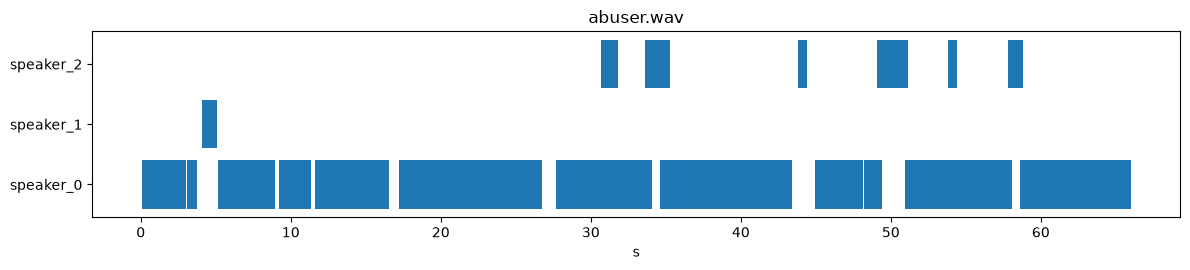

In [34]:
rttm = out_dir / f"{audio_path.stem}.rttm"
with open(rttm, "w") as f:
    for s, e, spk in turns:
        f.write(f"SPEAKER {audio_path.stem} 1 {s:.3f} {e - s:.3f} <NA> <NA> {spk} <NA> <NA>\n")
print("saved", rttm.relative_to(root))

speakers = sorted({spk for *_, spk in turns})
for spk in speakers:
    print(spk, round(sum(e - s for s, e, x in turns if x == spk), 1), "s")

fig, ax = plt.subplots(figsize=(12, 0.6 * len(speakers) + 1))
for row, spk in enumerate(speakers):
    ax.broken_barh([(s, e - s) for s, e, x in turns if x == spk], (row - 0.4, 0.8))
ax.set_yticks(range(len(speakers)), speakers)
ax.set_xlabel("s")
ax.set_title(audio_path.name)
plt.tight_layout()
plt.show()

In [35]:

import json
import soundfile as sf
from pathlib import Path

# Load the same audio used for diarization (16 kHz mono)
audio, sr = sf.read(model_audio)

# Output directory
chunk_dir = root / "outputs" / "chunks" / audio_path.stem / "diarization_turns"
chunk_dir.mkdir(parents=True, exist_ok=True)

manifest = []

for i, (start, end, speaker) in enumerate(turns):

    # Convert seconds to sample indices
    start_sample = max(0, round(start * sr))
    end_sample = min(len(audio), round(end * sr))

    if end_sample <= start_sample:
        continue

    # Extract audio segment
    chunk = audio[start_sample:end_sample]

    # Save WAV
    filename = f"{i:04d}_{speaker}.wav"
    filepath = chunk_dir / filename

    sf.write(filepath, chunk, sr)

    manifest.append({
        "audio_filepath": str(filepath),
        "start": start,
        "end": end,
        "duration": len(chunk) / sr,
        "speaker": speaker
    })

# Save metadata
with open(chunk_dir / "manifest.jsonl", "w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Saved {len(manifest)} chunks to {chunk_dir}")


Saved 21 chunks to /Users/macbook/Documents/IT/projects/tts/outputs/chunks/abuser/diarization_turns


In [36]:

import json
import soundfile as sf
from pathlib import Path

# Load the same audio used for diarization (16 kHz mono)
audio, sr = sf.read(model_audio)

# Output directory
chunk_dir = root / "outputs" / "chunks" / audio_path.stem / "diarization_turns"
chunk_dir.mkdir(parents=True, exist_ok=True)

manifest = []

for i, (start, end, speaker) in enumerate(turns):

    # Convert seconds to sample indices
    start_sample = max(0, round(start * sr))
    end_sample = min(len(audio), round(end * sr))

    if end_sample <= start_sample:
        continue

    # Extract audio segment
    chunk = audio[start_sample:end_sample]

    # Save WAV
    filename = f"{i:04d}_{speaker}.wav"
    filepath = chunk_dir / filename

    sf.write(filepath, chunk, sr)

    manifest.append({
        "audio_filepath": str(filepath),
        "start": start,
        "end": end,
        "duration": len(chunk) / sr,
        "speaker": speaker
    })

# Save metadata
with open(chunk_dir / "manifest.jsonl", "w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Saved {len(manifest)} chunks to {chunk_dir}")


Saved 21 chunks to /Users/macbook/Documents/IT/projects/tts/outputs/chunks/abuser/diarization_turns


In [37]:

import numpy as np
import soundfile as sf

audio, sr = sf.read(model_audio)
total_seconds = len(audio) / sr

# Create one activity mask per speaker.
speakers = sorted(set(spk for _, _, spk in turns))
masks = {}

for speaker in speakers:
    mask = np.zeros(len(audio), dtype=bool)

    for start, end, spk in turns:
        if spk == speaker:
            a = max(0, round(start * sr))
            b = min(len(audio), round(end * sr))
            mask[a:b] = True

    masks[speaker] = mask

# How many distinct speakers are active at each sample?
activity = np.zeros(len(audio), dtype=np.int16)
for mask in masks.values():
    activity += mask.astype(np.int16)

speech_seconds = np.count_nonzero(activity >= 1) / sr
overlap_seconds = np.count_nonzero(activity >= 2) / sr
non_speech_seconds = total_seconds - speech_seconds

print(f"Total audio: {total_seconds:.2f}s")
print(f"Speech present: {speech_seconds / total_seconds * 100:.1f}%")
print(f"Non-speech: {non_speech_seconds / total_seconds * 100:.1f}%")
print(f"Overlapping speakers: {overlap_seconds / total_seconds * 100:.1f}%")


Total audio: 69.20s
Speech present: 90.4%
Non-speech: 9.6%
Overlapping speakers: 5.5%


In [38]:

import numpy as np
import torch
import soundfile as sf
from silero_vad import load_silero_vad, get_speech_timestamps

audio, sr = sf.read(model_audio, dtype="float32")

assert audio.ndim == 1, "Expected mono audio"
assert sr == 16000, "Expected 16 kHz audio"

model = load_silero_vad()

# Detect speech timestamps in samples
timestamps = get_speech_timestamps(
    torch.from_numpy(audio.copy()),
    model,
    sampling_rate=sr,
    threshold=0.5,
    speech_pad_ms=0,
)

# Mark every sample containing detected speech
speech_mask = np.zeros(len(audio), dtype=bool)

for segment in timestamps:
    speech_mask[segment["start"]:segment["end"]] = True

# Classify the recording in 100 ms frames
frame_size = int(sr * 0.1)
durations = {
    "speech": 0.0,
    "other_sound": 0.0,
    "near_silence": 0.0,
}

# Adjustable energy threshold, not a universal noise detector
SILENCE_DBFS = -40

for start in range(0, len(audio), frame_size):
    end = min(start + frame_size, len(audio))
    frame = audio[start:end]
    duration = len(frame) / sr

    speech_fraction = speech_mask[start:end].mean()
    rms = np.sqrt(np.mean(frame.astype(np.float64) ** 2))
    dbfs = 20 * np.log10(max(rms, 1e-10))

    if speech_fraction >= 0.5:
        category = "speech"
    elif dbfs > SILENCE_DBFS:
        category = "other_sound"
    else:
        category = "near_silence"

    durations[category] += duration

total = len(audio) / sr

for category, seconds in durations.items():
    percentage = seconds / total * 100
    print(f"{category}: {percentage:.1f}% ({seconds:.2f}s)")


speech: 91.3% (63.20s)
other_sound: 1.0% (0.70s)
near_silence: 7.7% (5.30s)


In [39]:
turns

[(0.06, 3.0, 'speaker_0'),
 (3.05, 3.77, 'speaker_0'),
 (4.09, 5.08, 'speaker_1'),
 (5.17, 8.98, 'speaker_0'),
 (9.23, 11.36, 'speaker_0'),
 (11.61, 16.53, 'speaker_0'),
 (16.99, 17.04, 'speaker_1'),
 (17.2, 26.76, 'speaker_0'),
 (27.65, 34.08, 'speaker_0'),
 (30.7, 31.78, 'speaker_2'),
 (33.6, 35.26, 'speaker_2'),
 (34.64, 43.44, 'speaker_0'),
 (43.8, 44.41, 'speaker_2'),
 (44.94, 48.08, 'speaker_0'),
 (48.09, 48.16, 'speaker_0'),
 (48.19, 49.4, 'speaker_0'),
 (49.06, 51.16, 'speaker_2'),
 (50.93, 58.09, 'speaker_0'),
 (53.78, 54.4, 'speaker_2'),
 (57.81, 58.81, 'speaker_2'),
 (58.64, 65.98, 'speaker_0')]

In [40]:

import soundfile as sf
import json
from pathlib import Path

# Uses existing variables: turns, model_audio, root, audio_path
MAX_GAP_SEC = 1.0  # Merge same speaker if gap <= 1 second

# 1. Merge consecutive same-speaker turns
merged = []

for start, end, speaker in sorted(turns):
    if merged:
        prev = merged[-1]
        
        if (speaker == prev[2] 
                and start - prev[1] <= MAX_GAP_SEC):
            prev[1] = max(prev[1], end)
            continue

    merged.append([start, end, speaker])

# 2. Load audio
audio, sr = sf.read(model_audio)

# 3. Create output folder
out_dir = (
    root / "outputs" / "chunks"
    / audio_path.stem / "merged_speakers"
)
out_dir.mkdir(parents=True, exist_ok=True)

# 4. Export merged WAV files
manifest = []

for i, (start, end, speaker) in enumerate(merged):
    a = max(0, round(start * sr))
    b = min(len(audio), round(end * sr))

    if b <= a:
        continue

    chunk = audio[a:b]
    filename = f"{i:04d}_{speaker}.wav"
    filepath = out_dir / filename

    sf.write(filepath, chunk, sr)

    manifest.append({
        "audio_filepath": str(filepath),
        "start": start,
        "end": end,
        "duration": len(chunk) / sr,
        "speaker": speaker
    })

# 5. Save metadata
with open(out_dir / "manifest.jsonl", "w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 6. Print results
print(f"Original turns: {len(turns)}")
print(f"Merged chunks: {len(manifest)}")

for item in manifest:
    print(
        f"{item['speaker']:12}"
        f"{item['start']:7.2f} – {item['end']:7.2f}"
    )


Original turns: 21
Merged chunks: 15
speaker_0      0.06 –    3.77
speaker_1      4.09 –    5.08
speaker_0      5.17 –   16.53
speaker_1     16.99 –   17.04
speaker_0     17.20 –   34.08
speaker_2     30.70 –   31.78
speaker_2     33.60 –   35.26
speaker_0     34.64 –   43.44
speaker_2     43.80 –   44.41
speaker_0     44.94 –   49.40
speaker_2     49.06 –   51.16
speaker_0     50.93 –   58.09
speaker_2     53.78 –   54.40
speaker_2     57.81 –   58.81
speaker_0     58.64 –   65.98
